In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
cancer_df = pd.read_csv('_cancer_dataset_uae.csv')

cancer_df.head()

,Patient_ID,Age,Gender,Nationality,Emirate,Diagnosis_Date,Cancer_Type,Cancer_Stage,Treatment_Type,Treatment_Start_Date,Hospital,Primary_Physician,Outcome,Death_Date,Cause_of_Death,Smoking_Status,Comorbidities,Ethnicity,Weight,Height
0,PAT000001,69,Female,Emirati,Umm Al Quwain,2020-11-30,Liver,II,Radiation,2020-12-04,Sheikh Khalifa Hospital,Dr. VO41,Recovered,NaN,NaN,Non-Smoker,NaN,European,61,157
1,PAT000002,32,Male,Emirati,Umm Al Quwain,2015-10-10,Leukemia,III,Surgery,2015-11-05,Dubai Hospital,Dr. SM31,Recovered,NaN,NaN,Smoker,NaN,South Asian,80,175
2,PAT000003,89,Male,Emirati,Abu Dhabi,2018-02-13,Liver,III,Radiation,2018-08-03,Zayed Military Hospital,Dr. BC7,Under Treatment,NaN,NaN,Non-Smoker,NaN,South Asian,50,175
3,PAT000004,78,Female,Emirati,Abu Dhabi,2022-02-04,Lung,III,Radiation,2022-03-13,Cleveland Clinic Abu Dhabi,Dr. TC14,Recovered,NaN,NaN,Former Smoker,NaN,African,44,155
4,PAT000005,38,Female,Emirati,Fujairah,2019-12-03,Pancreatic,II,Chemotherapy,2020-02-29,Sheikh Khalifa Hospital,Dr. YS37,Recovered,NaN,NaN,Former Smoker,NaN,East Asian,101,160


In [3]:
#shape of dataset
cancer_df.shape

(10000, 20)

In [4]:
#data information
cancer_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Patient_ID            10000 non-null  object
 1   Age                   10000 non-null  int64 
 2   Gender                10000 non-null  object
 3   Nationality           10000 non-null  object
 4   Emirate               10000 non-null  object
 5   Diagnosis_Date        10000 non-null  object
 6   Cancer_Type           10000 non-null  object
 7   Cancer_Stage          10000 non-null  object
 8   Treatment_Type        10000 non-null  object
 9   Treatment_Start_Date  10000 non-null  object
 10  Hospital              10000 non-null  object
 11  Primary_Physician     10000 non-null  object
 12  Outcome               10000 non-null  object
 13  Death_Date            992 non-null    object
 14  Cause_of_Death        992 non-null    object
 15  Smoking_Status        10000 non-null 

In [5]:
#check for missing values
cancer_df.isna().sum()

Patient_ID                 0
Age                        0
Gender                     0
Nationality                0
Emirate                    0
Diagnosis_Date             0
Cancer_Type                0
Cancer_Stage               0
Treatment_Type             0
Treatment_Start_Date       0
Hospital                   0
Primary_Physician          0
Outcome                    0
Death_Date              9008
Cause_of_Death          9008
Smoking_Status             0
Comorbidities           4047
Ethnicity                  0
Weight                     0
Height                     0
dtype: int64

In [6]:
#fill missing comorbidities: blank means no comorbidity recorded
cancer_df['Comorbidities'] = cancer_df['Comorbidities'].fillna('None')
cancer_df['Comorbidities'].value_counts()

Comorbidities
None                      4047
Hypertension              2945
Diabetes                  2005
Cardiovascular Disease    1003
Name: count, dtype: int64

In [7]:
#view rows containing missing values
cancer_df[cancer_df['Cause_of_Death'].isna()]

,Patient_ID,Age,Gender,Nationality,Emirate,Diagnosis_Date,Cancer_Type,Cancer_Stage,Treatment_Type,Treatment_Start_Date,Hospital,Primary_Physician,Outcome,Death_Date,Cause_of_Death,Smoking_Status,Comorbidities,Ethnicity,Weight,Height
0,PAT000001,69,Female,Emirati,Umm Al Quwain,2020-11-30,Liver,II,Radiation,2020-12-04,Sheikh Khalifa Hospital,Dr. VO41,Recovered,NaN,NaN,Non-Smoker,None,European,61,157
1,PAT000002,32,Male,Emirati,Umm Al Quwain,2015-10-10,Leukemia,III,Surgery,2015-11-05,Dubai Hospital,Dr. SM31,Recovered,NaN,NaN,Smoker,None,South Asian,80,175
2,PAT000003,89,Male,Emirati,Abu Dhabi,2018-02-13,Liver,III,Radiation,2018-08-03,Zayed Military Hospital,Dr. BC7,Under Treatment,NaN,NaN,Non-Smoker,None,South Asian,50,175
3,PAT000004,78,Female,Emirati,Abu Dhabi,2022-02-04,Lung,III,Radiation,2022-03-13,Cleveland Clinic Abu Dhabi,Dr. TC14,Recovered,NaN,NaN,Former Smoker,None,African,44,155
4,PAT000005,38,Female,Emirati,Fujairah,2019-12-03,Pancreatic,II,Chemotherapy,2020-02-29,Sheikh Khalifa Hospital,Dr. YS37,Recovered,NaN,NaN,Former Smoker,None,East Asian,101,160
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,PAT009996,88,Male,Emirati,Ras Al Khaimah,2016-01-21,Ovarian,II,Surgery,2016-04-03,Sheikh Khalifa Hospital,Dr. FJ27,Recovered,NaN,NaN,Smoker,Cardiovascular Disease,European,55,168
9996,PAT009997,43,Male,Emirati,Sharjah,2018-12-06,Ovarian,III,Radiation,2019-03-23,Cleveland Clinic Abu Dhabi,Dr. JB17,Under Treatment,NaN,NaN,Non-Smoker,Diabetes,African,98,175
9997,PAT009998,63,Female,Emirati,Sharjah,2016-06-11,Lung,III,Chemotherapy,2016-10-21,Dubai Hospital,Dr. ZG45,Under Treatment,NaN,NaN,Non-Smoker,None,East Asian,92,165
9998,PAT009999,63,Female,Emirati,Abu Dhabi,2018-11-12,Lung,IV,Immunotherapy,2019-02-05,Cleveland Clinic Abu Dhabi,Dr. EL16,Recovered,NaN,NaN,Smoker,Hypertension,European,68,193


In [8]:
#check for duplicates
cancer_df.duplicated().sum()

np.int64(0)

In [9]:
#checking data type
cancer_df['Diagnosis_Date'].dtype

dtype('O')

In [10]:
import datetime as dt

#convert to date data type
cancer_df['Diagnosis_Date'] = pd.to_datetime(cancer_df['Diagnosis_Date'])

cancer_df['Treatment_Start_Date'] = pd.to_datetime(cancer_df['Treatment_Start_Date'])


In [11]:
#view columns
cancer_df[['Diagnosis_Date', 'Treatment_Start_Date']]

,Diagnosis_Date,Treatment_Start_Date
0,2020-11-30,2020-12-04
1,2015-10-10,2015-11-05
2,2018-02-13,2018-08-03
3,2022-02-04,2022-03-13
4,2019-12-03,2020-02-29
...,...,...
9995,2016-01-21,2016-04-03
9996,2018-12-06,2019-03-23
9997,2016-06-11,2016-10-21
9998,2018-11-12,2019-02-05


In [12]:
cancer_df[['Diagnosis_Date', 'Treatment_Start_Date']].dtypes

Diagnosis_Date          datetime64[ns]
Treatment_Start_Date    datetime64[ns]
dtype: object

In [13]:
#check for the number of unique ages in the age category
print('Count of unique ages :', cancer_df['Age'].nunique())

print('\n')
#check for the unique ages in the age category
print('unique ages :', cancer_df['Age'].unique())

Count of unique ages : 72


unique ages : [69 32 89 78 38 41 20 39 70 19 47 55 81 77 50 75 66 76 59 79 64 68 72 24
 56 35 21 31 26 88 61 25 52 53 67 23 71 80 51 65 57 43 58 46 62 82 18 28
 22 45 29 40 54 44 60 30 49 83 74 87 73 36 85 34 86 33 37 84 48 42 63 27]


In [14]:
print(cancer_df['Age'].describe())

#create bins for the various age categories
twenty_fifth = cancer_df['Age'].quantile(0.25)
median = cancer_df['Age'].median()
seventy_fifth = cancer_df['Age'].quantile(0.75)
maximum = cancer_df['Age'].max()

#create a label and bins for the various age categories
labels = ['young_adult','middle_age','older_adult','elderlies']
bins = [0, twenty_fifth, median, seventy_fifth, maximum]

#create a category column for age
cancer_df['Age_cat'] = pd.cut(cancer_df['Age'], labels=labels, bins=bins)

count    10000.000000
mean        53.539700
std         20.757324
min         18.000000
25%         36.000000
50%         53.000000
75%         72.000000
max         89.000000
Name: Age, dtype: float64


In [15]:
cancer_df[['Age', 'Age_cat']]

,Age,Age_cat
0,69,older_adult
1,32,young_adult
2,89,elderlies
3,78,elderlies
4,38,middle_age
...,...,...
9995,88,elderlies
9996,43,middle_age
9997,63,older_adult
9998,63,older_adult


In [16]:
for x in cancer_df.columns:
    print(cancer_df[x].unique())

['PAT000001' 'PAT000002' 'PAT000003' ... 'PAT009998' 'PAT009999'
 'PAT010000']
[69 32 89 78 38 41 20 39 70 19 47 55 81 77 50 75 66 76 59 79 64 68 72 24
 56 35 21 31 26 88 61 25 52 53 67 23 71 80 51 65 57 43 58 46 62 82 18 28
 22 45 29 40 54 44 60 30 49 83 74 87 73 36 85 34 86 33 37 84 48 42 63 27]
['Female' 'Male' 'Other']
['Emirati' 'Expatriate']
['Umm Al Quwain' 'Abu Dhabi' 'Fujairah' 'Ras Al Khaimah' 'Sharjah' 'Dubai'
 'Ajman']
<DatetimeArray>
['2020-11-30 00:00:00', '2015-10-10 00:00:00', '2018-02-13 00:00:00',
 '2022-02-04 00:00:00', '2019-12-03 00:00:00', '2015-02-10 00:00:00',
 '2023-02-27 00:00:00', '2018-04-05 00:00:00', '2022-12-12 00:00:00',
 '2018-05-29 00:00:00',
 ...
 '2018-01-18 00:00:00', '2020-12-30 00:00:00', '2020-12-15 00:00:00',
 '2018-10-05 00:00:00', '2020-07-25 00:00:00', '2018-05-14 00:00:00',
 '2016-06-09 00:00:00', '2019-06-21 00:00:00', '2022-09-18 00:00:00',
 '2016-06-11 00:00:00']
Length: 3151, dtype: datetime64[ns]
['Liver' 'Leukemia' 'Lung' 'Pancreatic' 

In [17]:
#statistical view of the categorical column

cancer_df.select_dtypes(include='object').describe()

,Patient_ID,Gender,Nationality,Emirate,Cancer_Type,Cancer_Stage,Treatment_Type,Hospital,Primary_Physician,Outcome,Death_Date,Cause_of_Death,Smoking_Status,Comorbidities,Ethnicity
count,10000,10000,10000,10000,10000,10000,10000,10000,10000,10000,992,992,10000,10000,10000
unique,10000,3,2,7,8,4,4,4,8614,3,867,2,3,4,5
top,PAT000001,Female,Emirati,Ajman,Leukemia,III,Radiation,Sheikh Khalifa Hospital,Dr. AJ25,Recovered,2022-06-28 00:00:00,Complications,Non-Smoker,None,South Asian
freq,1,4985,5920,1497,1314,3041,2519,2541,5,4931,3,507,5038,4047,2083


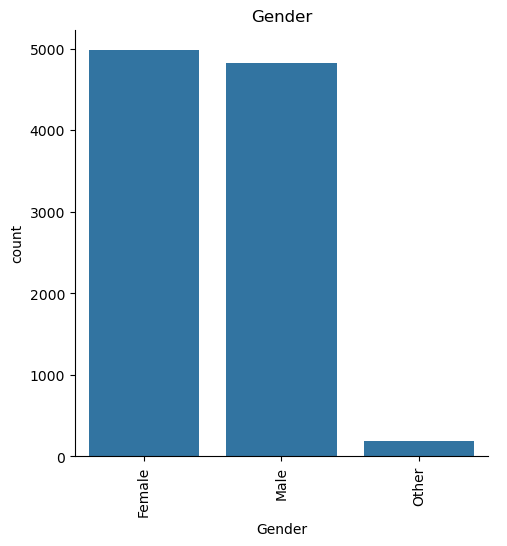

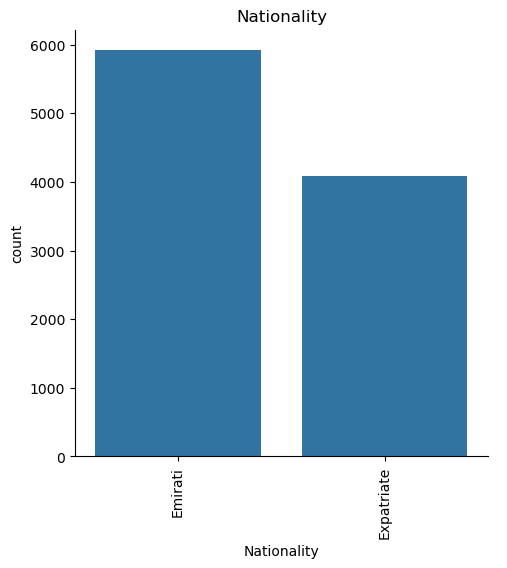

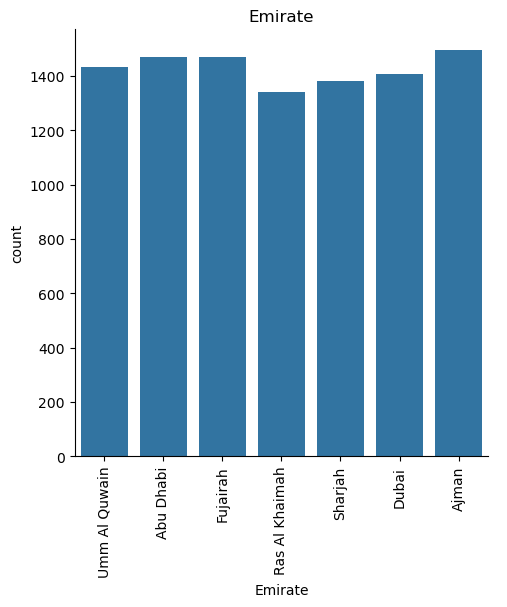

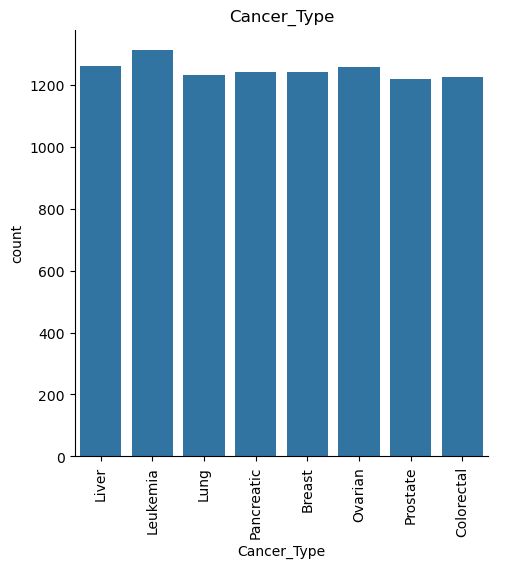

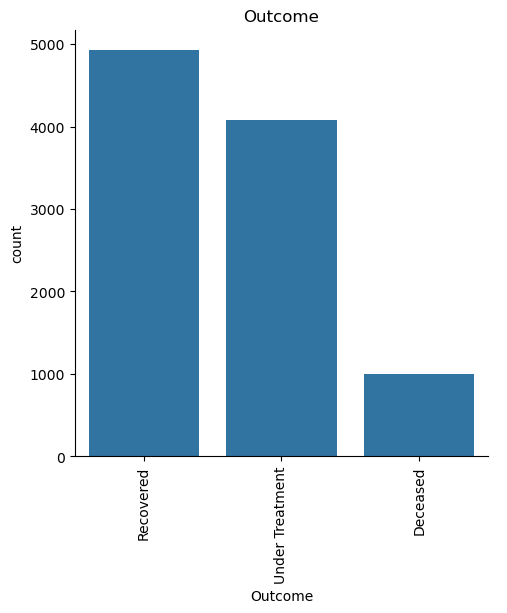

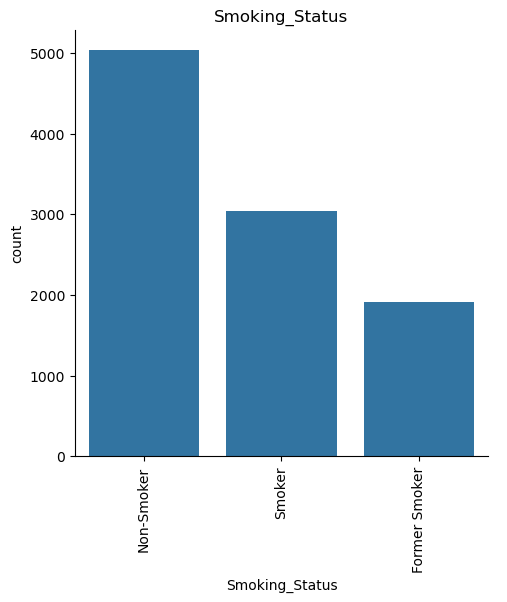

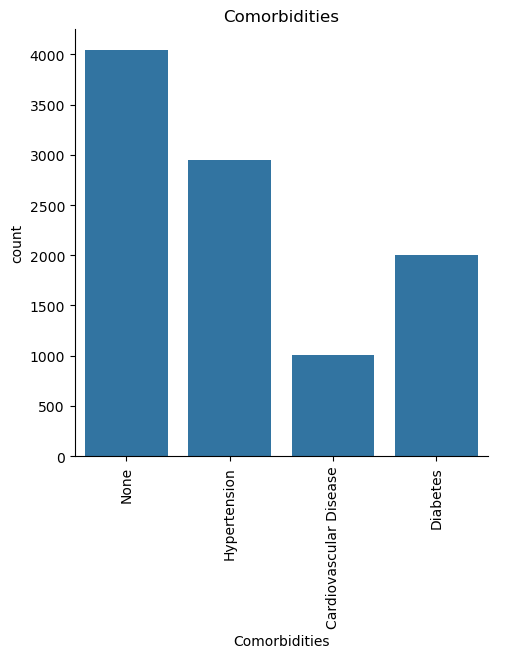

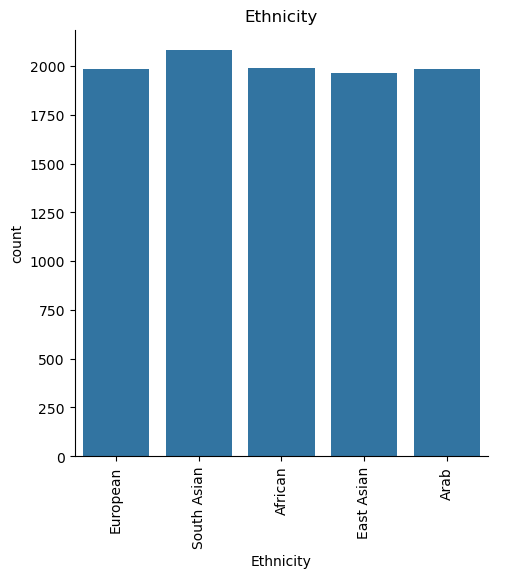

In [18]:
column_list = ['Gender', 'Nationality', 'Emirate', 'Cancer_Type',
               'Outcome', 'Smoking_Status', 'Comorbidities', 'Ethnicity']

def plot_bar_graph():
    for c in column_list:
        g = sns.catplot(x=c, data=cancer_df, kind='count')
        g.set_xticklabels(rotation=90)

        plt.title(c)
        plt.show()

plot_bar_graph()

In [19]:
#statistical view of the numerical column
cancer_df.describe()

,Age,Diagnosis_Date,Treatment_Start_Date,Weight,Height
count,10000.000000,10000,10000,10000.000000,10000.000000
mean,53.539700,2019-08-08 15:31:58.080000,2019-11-05 23:51:38.880000,69.550000,169.347500
min,18.000000,2015-01-01 00:00:00,2015-01-07 00:00:00,18.000000,131.000000
25%,36.000000,2017-04-05 00:00:00,2017-07-05 00:00:00,60.000000,163.000000
50%,53.000000,2019-08-26 12:00:00,2019-11-24 00:00:00,70.000000,169.000000
75%,72.000000,2021-11-22 00:00:00,2022-02-18 00:00:00,80.000000,176.000000
max,89.000000,2024-03-01 00:00:00,2024-08-23 00:00:00,122.000000,208.000000
std,20.757324,NaN,NaN,14.933339,10.070118


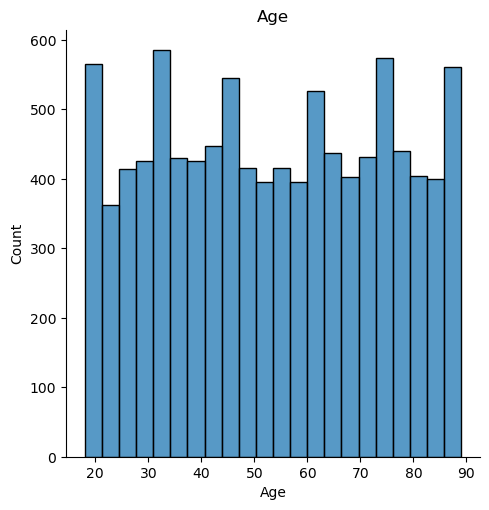

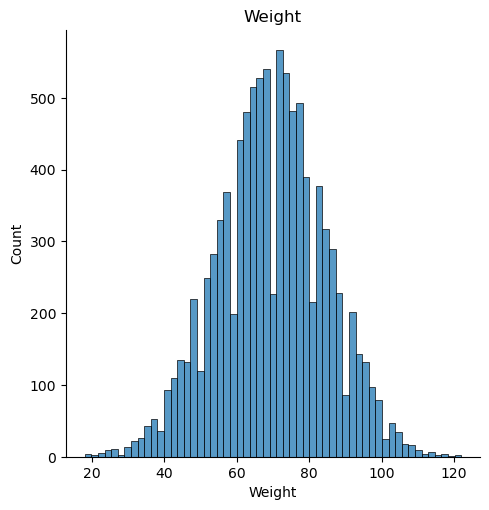

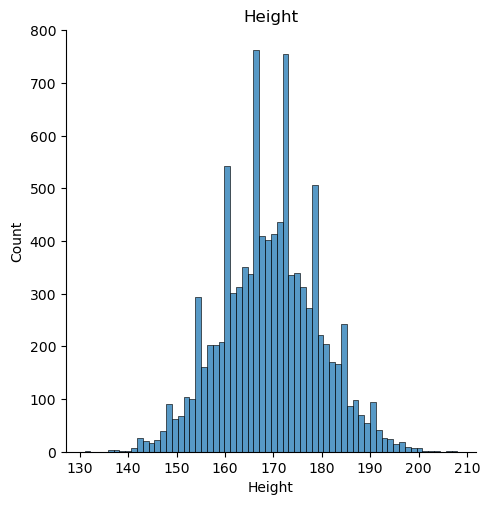

In [20]:
col = ['Age','Weight','Height']

def plot_bar_graph():
    for c in col:
        sns.displot(cancer_df[c])

        plt.title(c)
        plt.show()

plot_bar_graph()

In [21]:
skew_value = cancer_df['Age'].skew()
print(f"Skewness of Age column: {skew_value}")

if skew_value > 0.5 : 
    print('Right-skewed (positive skew): tail is longer on the right')
elif skew_value < -0.5 :
    print('Left-skewed (negative skew): tail is longer on the left')
else:
    print('Approximately symmetrical')

Skewness of Age column: 0.003845595965890207
Approximately symmetrical


In [22]:
# Assuming df is your DataFrame and 'Age' is the column of interest
Q1 = cancer_df['Age'].quantile(0.25)
Q3 = cancer_df['Age'].quantile(0.75)
IQR = Q3 - Q1

# Define bounds for outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR 

In [23]:
# filter out the outliers
outliers = cancer_df[(cancer_df['Age'] < lower_bound) | (cancer_df['Age'] > upper_bound)]

print(outliers)

Empty DataFrame
Columns: [Patient_ID, Age, Gender, Nationality, Emirate, Diagnosis_Date, Cancer_Type, Cancer_Stage, Treatment_Type, Treatment_Start_Date, Hospital, Primary_Physician, Outcome, Death_Date, Cause_of_Death, Smoking_Status, Comorbidities, Ethnicity, Weight, Height, Age_cat]
Index: []

[0 rows x 21 columns]


In [24]:
# Assuming df is your DataFrame and 'Age' is the column of interest
Q1 = cancer_df['Weight'].quantile(0.25)
Q3 = cancer_df['Weight'].quantile(0.75)
IQR = Q3 - Q1

# Define bounds for outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [25]:
# Filter out the outliers
outliers = cancer_df[(cancer_df['Weight'] < lower_bound) | (cancer_df['Weight'] > upper_bound)]

print(outliers['Weight'].unique())

[ 27  18 117  24 112  28  29  23 118  26 111 114  25 122 113 116 120  19
  21  22 115]


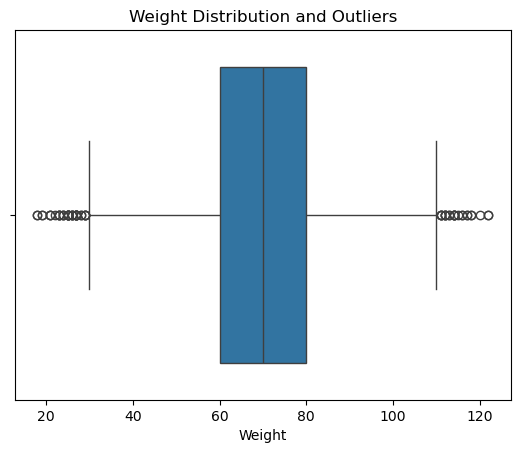

In [26]:
sns.boxplot(x='Weight', data=cancer_df)
plt.title('Weight Distribution and Outliers')
plt.savefig('weight_outliers.png', dpi=150, bbox_inches='tight')
plt.show()

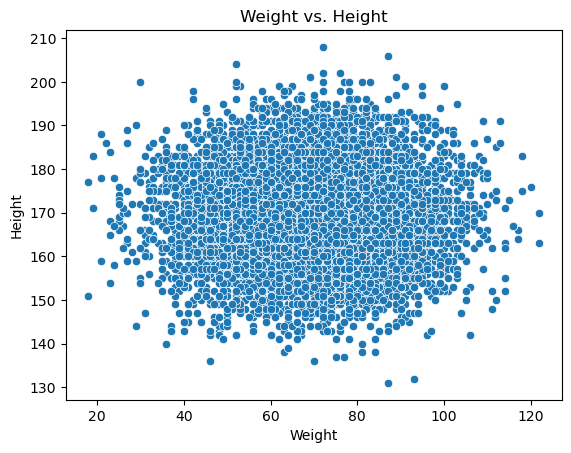

In [27]:
#scatterplot showing relationship between weight and height

sns.scatterplot(x='Weight', y='Height', data=cancer_df)
plt.title('Weight vs. Height')
plt.show()

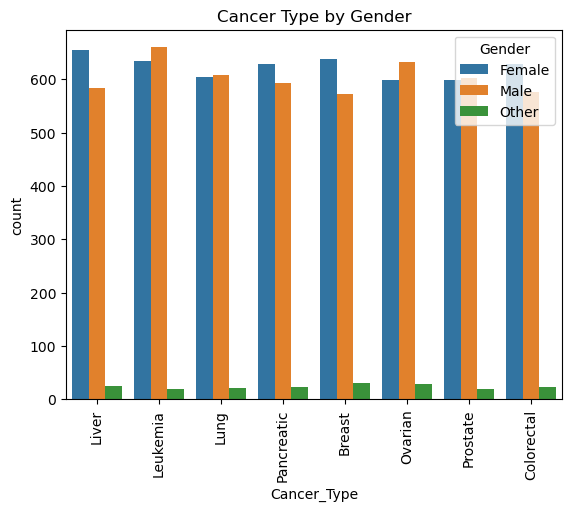

In [28]:
#distribution of cancer type for gender

sns.countplot(hue='Gender', x='Cancer_Type', data=cancer_df)

plt.xticks(rotation=90)
plt.title('Cancer Type by Gender')
plt.savefig('cancer_type_by_gender.png', dpi=150, bbox_inches='tight')
plt.show()

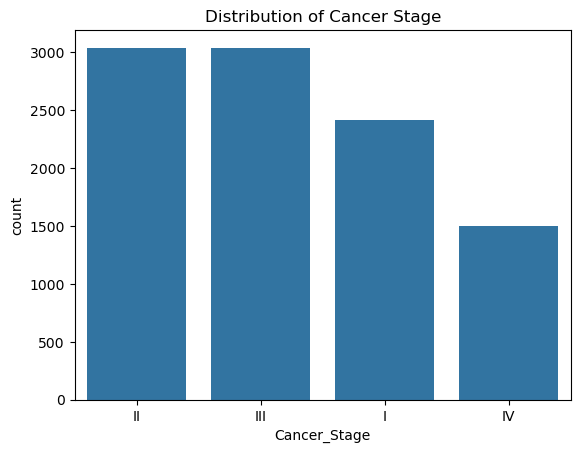

In [29]:
#distribution of cancer stage
sns.countplot(x='Cancer_Stage', data=cancer_df)
plt.title('Distribution of Cancer Stage')
plt.show()

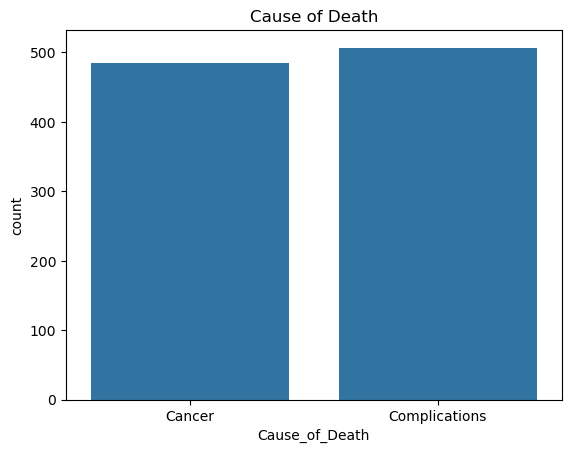

In [30]:
#distribution of cause of death

sns.countplot(x='Cause_of_Death', data=cancer_df)
plt.title('Cause of Death')
plt.show()

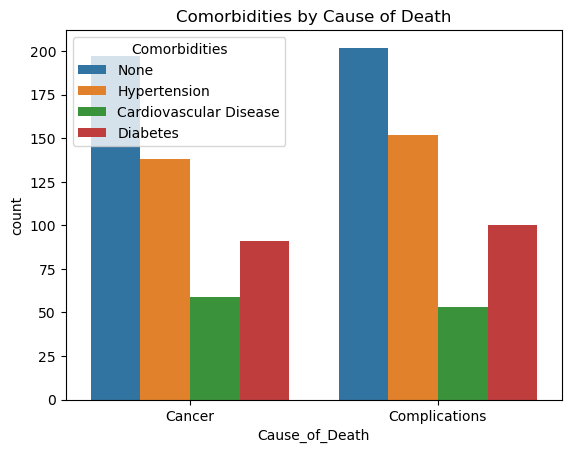

In [31]:
#Cormobidities associated with causes of death

sns.countplot(x='Cause_of_Death',hue='Comorbidities', data=cancer_df)
plt.title('Comorbidities by Cause of Death')
plt.show()

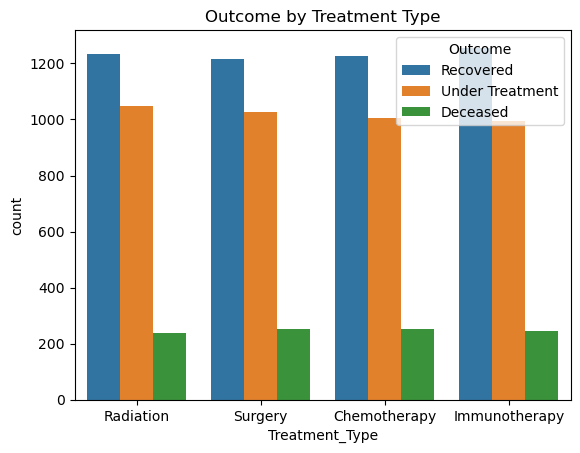

In [32]:
#outcome for various treatment type

sns.countplot(x='Treatment_Type', hue='Outcome', data=cancer_df)
plt.title('Outcome by Treatment Type')
plt.savefig('outcome_by_treatment.png', dpi=150, bbox_inches='tight')
plt.show()

In [33]:
cancer_df['Time_delta'] = cancer_df['Treatment_Start_Date'] - cancer_df['Diagnosis_Date']

cancer_df['Time_delta']

0        4 days
1       26 days
2      171 days
3       37 days
4       88 days
         ...   
9995    73 days
9996   107 days
9997   132 days
9998    85 days
9999    98 days
Name: Time_delta, Length: 10000, dtype: timedelta64[ns]

In [34]:
cancer_df['Time_delta'].describe()

count                         10000
mean        89 days 08:19:40.800000
std      52 days 07:11:18.298964457
min                 0 days 00:00:00
25%                44 days 00:00:00
50%                90 days 00:00:00
75%               135 days 00:00:00
max               179 days 00:00:00
Name: Time_delta, dtype: object

In [35]:
#check for the number of unique Time_delta
print('Count of unique Time_delta :', cancer_df['Time_delta'].nunique())

#create bins for the various age of categories
min_day = cancer_df['Time_delta'].min()
twenty_fifth = cancer_df['Time_delta'].quantile(0.25)
median = cancer_df['Time_delta'].median()
seventy_fifth = cancer_df['Time_delta'].quantile(0.75)
maximum = cancer_df['Time_delta'].max()

#create a label and bins for the various age categories
labels = ['Immediate Start', 'Early Start', 'Moderate Delay', 'Delayed Start']
bins = [min_day, twenty_fifth, median, seventy_fifth, maximum]

#create a category column for age
cancer_df['Time_delta_cat'] = pd.cut(cancer_df['Time_delta'], labels=labels, bins=bins, include_lowest=True)

Count of unique Time_delta : 180


In [36]:
cancer_df[['Time_delta','Time_delta_cat']]

,Time_delta,Time_delta_cat
0,4 days,Immediate Start
1,26 days,Immediate Start
2,171 days,Delayed Start
3,37 days,Immediate Start
4,88 days,Early Start
...,...,...
9995,73 days,Early Start
9996,107 days,Moderate Delay
9997,132 days,Moderate Delay
9998,85 days,Early Start


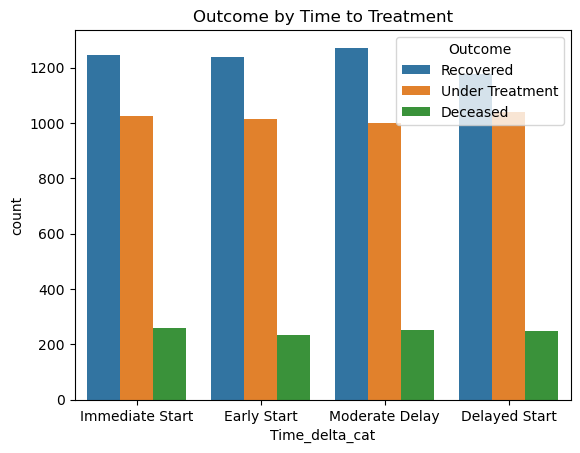

In [37]:
sns.countplot(x='Time_delta_cat', hue='Outcome', data=cancer_df)
plt.title('Outcome by Time to Treatment')
plt.savefig('outcome_by_time_to_treatment.png', dpi=150, bbox_inches='tight')
plt.show()

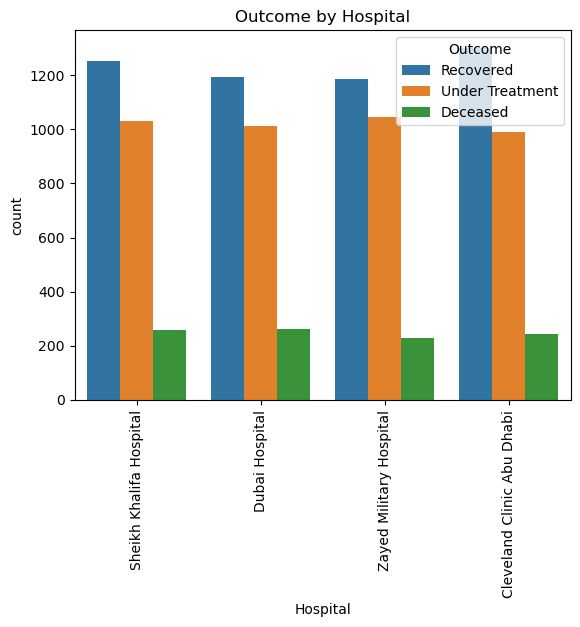

In [38]:
#Hospital and patient treatment outcome

sns.countplot(x='Hospital', hue='Outcome', data=cancer_df)

plt.xticks(rotation=90)
plt.title('Outcome by Hospital')
plt.show()

In [39]:
checks = {
    'Male with ovarian cancer': ((cancer_df['Gender'] == 'Male') & (cancer_df['Cancer_Type'] == 'Ovarian')).sum(),
    'Female with prostate cancer': ((cancer_df['Gender'] == 'Female') & (cancer_df['Cancer_Type'] == 'Prostate')).sum(),
    'Adult weight under 35 kg': (cancer_df['Weight'] < 35).sum(),
    'Death before diagnosis': (pd.to_datetime(cancer_df['Death_Date']) < cancer_df['Diagnosis_Date']).sum(),
    'Deceased with no death date': ((cancer_df['Outcome'] == 'Deceased') & cancer_df['Death_Date'].isna()).sum(),
}
pd.Series(checks, name='Count')

Male with ovarian cancer       632
Female with prostate cancer    598
Adult weight under 35 kg        97
Death before diagnosis           0
Deceased with no death date      0
Name: Count, dtype: int64

In [40]:
pd.crosstab(cancer_df['Cancer_Stage'], cancer_df['Outcome'], normalize='index').mul(100).round(1)

Outcome,Deceased,Recovered,Under Treatment
Cancer_Stage,,,
I,10.0,49.1,40.9
II,8.8,50.4,40.8
III,10.4,48.7,40.9
IV,11.0,48.7,40.2


In [41]:
pd.crosstab(cancer_df['Treatment_Type'], cancer_df['Outcome'], normalize='index').mul(100).round(1)

Outcome,Deceased,Recovered,Under Treatment
Treatment_Type,,,
Chemotherapy,10.2,49.3,40.5
Immunotherapy,9.9,50.3,39.8
Radiation,9.4,48.9,41.6
Surgery,10.2,48.7,41.1


In [42]:
pd.crosstab(cancer_df['Time_delta_cat'], cancer_df['Outcome'], normalize='index').mul(100).round(1)

Outcome,Deceased,Recovered,Under Treatment
Time_delta_cat,,,
Immediate Start,10.2,49.2,40.5
Early Start,9.4,49.8,40.8
Moderate Delay,10.0,50.4,39.6
Delayed Start,10.1,47.8,42.2


In [43]:
pd.crosstab(cancer_df['Smoking_Status'], cancer_df['Outcome'], normalize='index').mul(100).round(1)

Outcome,Deceased,Recovered,Under Treatment
Smoking_Status,,,
Former Smoker,10.2,48.5,41.4
Non-Smoker,9.8,49.9,40.3
Smoker,10.0,48.8,41.1


In [44]:
cancer_df['Time_delta_cat'].isna().sum()

np.int64(0)

In [45]:
(cancer_df['Time_delta'].dt.days == 0).sum()

np.int64(59)